# ERA5 Wind Speed Calibration: Diurnal & Directional Sector Regression

This notebook implements an advanced meteorological calibration algorithm to translate **ERA5 10m wind speed** into a reliable predictor of **ground-based wind conditions** observed at the ALMA site (5,000 meters altitude).

### Why Calibrate?
ERA5 is a global numerical weather prediction model with a horizontal grid spacing of ~31 km. At high altitudes and complex terrains like the Chilean Andes, the model cannot capture local topographically-driven wind features. The raw ERA5 data systematically underestimates the wind speed (Mean Bias Error of `-4.06 m/s`) and has a moderate correlation of `0.6734`.

### The Algorithm: Diurnal & Directional Sector Calibration
Instead of a simple constant offset (which does not improve the correlation), we use a non-linear calibration that bins data by:
1. **Hour of day (0-23)**: Captures the diurnal cycle of the atmospheric boundary layer and local wind patterns (e.g. daily slope winds).
2. **Wind Direction Sector (8 sectors)**: Captures speed-up or shielding effects from local topography (mountains) depending on wind direction (N, NE, E, SE, S, SW, W, NW).

For each of the 192 bins `(hour, sector)`, we fit a linear regression line ($v_{\text{measured}} = m \cdot v_{\text{ERA5}} + b$). When applied to the ERA5 timeseries, this non-linear mapping adjusts the magnitude, variance, and shape of the distribution, resulting in a higher correlation and lower root-mean-square error.

In [1]:
# ============================================================
# 1. IMPORTS & CONFIGURATION
# ============================================================
import os
import glob
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('default')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
print("Libraries loaded successfully! ✔")

Libraries loaded successfully! ✔


In [2]:
# ============================================================
# 2. LOAD PUBLISHED GROUND-BASED DATA
# ============================================================
pub_path = r"../data/exports/alma_published_timeseries.csv"
df_pub = pd.read_csv(pub_path, parse_dates=['datetime'])

# Drop rows with missing speed values (Column 7 / 'speed' is wind speed in m/s)
df_pub = df_pub.dropna(subset=['speed'])
print(f"Loaded {len(df_pub):,} valid ground-based hourly records.")

Loaded 15,632 valid ground-based hourly records.


In [3]:
# ============================================================
# 3. LOAD ERA5 DATA WITH WIND COMPONENTS
# ============================================================
ALMA_LAT = -23.029
ALMA_LON = -67.755

chile_files = sorted(glob.glob(r"../data/raw/chile/chile_*.nc"))
print(f"Found {len(chile_files)} ERA5 NetCDF files.")

era5_records = []
for f in chile_files:
    with xr.open_dataset(f) as ds:
        # Extract nearest grid point to ALMA site
        point_ds = ds.sel(latitude=ALMA_LAT, longitude=ALMA_LON, method='nearest')
        u10 = point_ds['u10'].values
        v10 = point_ds['v10'].values
        ws10 = np.sqrt(u10**2 + v10**2)
        
        df_pt = pd.DataFrame({
            'datetime': point_ds['valid_time'].values,
            'era5_speed': ws10,
            'era5_u10': u10,
            'era5_v10': v10
        })
        era5_records.append(df_pt)

df_era5 = pd.concat(era5_records, ignore_index=True)
print(f"Loaded {len(df_era5):,} ERA5 hourly records.")

Found 24 ERA5 NetCDF files.


Loaded 17,520 ERA5 hourly records.


In [4]:
# ============================================================
# 4. ALIGN DATASETS AND CALCULATE METEOROLOGICAL DIRECTIONS
# ============================================================
merged_df = pd.merge(df_pub, df_era5, on='datetime', how='inner')
merged_df = merged_df.dropna(subset=['speed', 'era5_speed'])
merged_df = merged_df.sort_values('datetime').reset_index(drop=True)

# Extract time components
merged_df['hour'] = merged_df['datetime'].dt.hour
merged_df['month'] = merged_df['datetime'].dt.month

# Calculate meteorological wind direction in degrees (direction FROM which wind is blowing)
merged_df['era5_dir'] = (np.degrees(np.arctan2(-merged_df['era5_u10'], -merged_df['era5_v10'])) + 360) % 360

# Define 8 wind direction sectors (45 degrees each)
def get_sector(deg):
    if (deg >= 337.5) or (deg < 22.5):
        return 'N'
    elif (deg >= 22.5) and (deg < 67.5):
        return 'NE'
    elif (deg >= 67.5) and (deg < 112.5):
        return 'E'
    elif (deg >= 112.5) and (deg < 157.5):
        return 'SE'
    elif (deg >= 157.5) and (deg < 202.5):
        return 'S'
    elif (deg >= 202.5) and (deg < 247.5):
        return 'SW'
    elif (deg >= 247.5) and (deg < 292.5):
        return 'W'
    else:
        return 'NW'

merged_df['sector'] = merged_df['era5_dir'].apply(get_sector)
print(f"Aligned dataset size: {len(merged_df):,} records.")
print(merged_df[['datetime', 'speed', 'era5_speed', 'era5_dir', 'sector']].head())

Aligned dataset size: 15,632 records.
             datetime  speed  era5_speed    era5_dir sector
0 2001-01-01 00:00:00    9.8    3.589680  260.138062      W
1 2001-01-01 01:00:00    6.6    1.797550  265.820862      W
2 2001-01-01 02:00:00    3.7    1.867238  268.981598      W
3 2001-01-01 03:00:00    1.6    1.000621  258.273346      W
4 2001-01-01 04:00:00    0.2    0.164233  336.533691     NW


In [5]:
# ============================================================
# 5. FIT AND APPLY DIURNAL-SECTOR CALIBRATION MODEL
# ============================================================
slopes = {}
intercepts = {}

# Train slopes and intercepts for each (hour, sector) bin
for (h, sec), group in merged_df.groupby(['hour', 'sector']):
    if len(group) > 5:
        slope, intercept = np.polyfit(group['era5_speed'], group['speed'], 1)
    else:
        # Fallback to general linear fit if data is sparse
        slope, intercept = np.polyfit(merged_df['era5_speed'], merged_df['speed'], 1)
    slopes[(h, sec)] = slope
    intercepts[(h, sec)] = intercept

# Apply bin-wise calibration
def apply_calibration(row):
    h = row['hour']
    sec = row['sector']
    slope = slopes.get((h, sec), 1.0)
    intercept = intercepts.get((h, sec), 0.0)
    return slope * row['era5_speed'] + intercept

merged_df['era5_speed_calibrated'] = merged_df.apply(apply_calibration, axis=1)

# Also calculate a simple mean offset for comparison
bias_orig = merged_df['era5_speed'].mean() - merged_df['speed'].mean()
merged_df['era5_speed_offset'] = merged_df['era5_speed'] - bias_orig
print("Calibration complete! Model parameter count: 192 bins (each with slope & intercept).")

Calibration complete! Model parameter count: 192 bins (each with slope & intercept).


In [6]:
# ============================================================
# 6. EVALUATE COMPARISON METRICS
# ============================================================
def calc_metrics(pred, truth):
    diff = pred - truth
    rmse = np.sqrt((diff ** 2).mean())
    bias = diff.mean()
    mae = diff.abs().mean()
    corr = truth.corr(pred)
    return bias, mae, rmse, corr

metrics_orig = calc_metrics(merged_df['era5_speed'], merged_df['speed'])
metrics_offset = calc_metrics(merged_df['era5_speed_offset'], merged_df['speed'])
metrics_cal = calc_metrics(merged_df['era5_speed_calibrated'], merged_df['speed'])

df_metrics = pd.DataFrame({
    'Metric': ['Mean Bias Error (MBE)', 'Mean Absolute Error (MAE)', 'Root Mean Sq. Error (RMSE)', 'Pearson Correlation (R)'],
    'Original ERA5': metrics_orig,
    'Mean-Offset ERA5': metrics_offset,
    'Calibrated ERA5 (Our Model)': metrics_cal
})
print("--- Model Evaluation Table ---")
print(df_metrics.to_string(index=False))

--- Model Evaluation Table ---
                    Metric  Original ERA5  Mean-Offset ERA5  Calibrated ERA5 (Our Model)
     Mean Bias Error (MBE)      -4.062584      9.528812e-08                    -0.010687
 Mean Absolute Error (MAE)       4.124695      2.300687e+00                     1.944140
Root Mean Sq. Error (RMSE)       5.029942      2.965758e+00                     2.562454
   Pearson Correlation (R)       0.673410      6.734103e-01                     0.757707


In [7]:
# ============================================================
# 7. PERCENTILE COMPARISON TABLE
# ============================================================
percentiles = [50, 90, 95, 99]
pub_pcts = [merged_df['speed'].quantile(p/100) for p in percentiles]
era5_orig_pcts = [merged_df['era5_speed'].quantile(p/100) for p in percentiles]
era5_offset_pcts = [merged_df['era5_speed_offset'].quantile(p/100) for p in percentiles]
era5_cal_pcts = [merged_df['era5_speed_calibrated'].quantile(p/100) for p in percentiles]

df_pct = pd.DataFrame({
    'Percentile': [f'P{p}' for p in percentiles],
    'Ground-Based (m/s)': pub_pcts,
    'Original ERA5 (m/s)': era5_orig_pcts,
    'Offset ERA5 (m/s)': era5_offset_pcts,
    'Calibrated ERA5 (m/s)': era5_cal_pcts,
    'Calibrated Error (m/s)': [c - g for g, c in zip(pub_pcts, era5_cal_pcts)]
})
print("--- Percentile Calibration Table ---")
print(df_pct.to_string(index=False))

--- Percentile Calibration Table ---
Percentile  Ground-Based (m/s)  Original ERA5 (m/s)  Offset ERA5 (m/s)  Calibrated ERA5 (m/s)  Calibrated Error (m/s)
       P50                 6.0             1.867969           5.930553               5.881065               -0.118935
       P90                11.8             5.789335           9.851919              10.916705               -0.883295
       P95                13.6             6.546185          10.608769              11.788295               -1.811705
       P99                17.6             8.061701          12.124286              13.866771               -3.733229


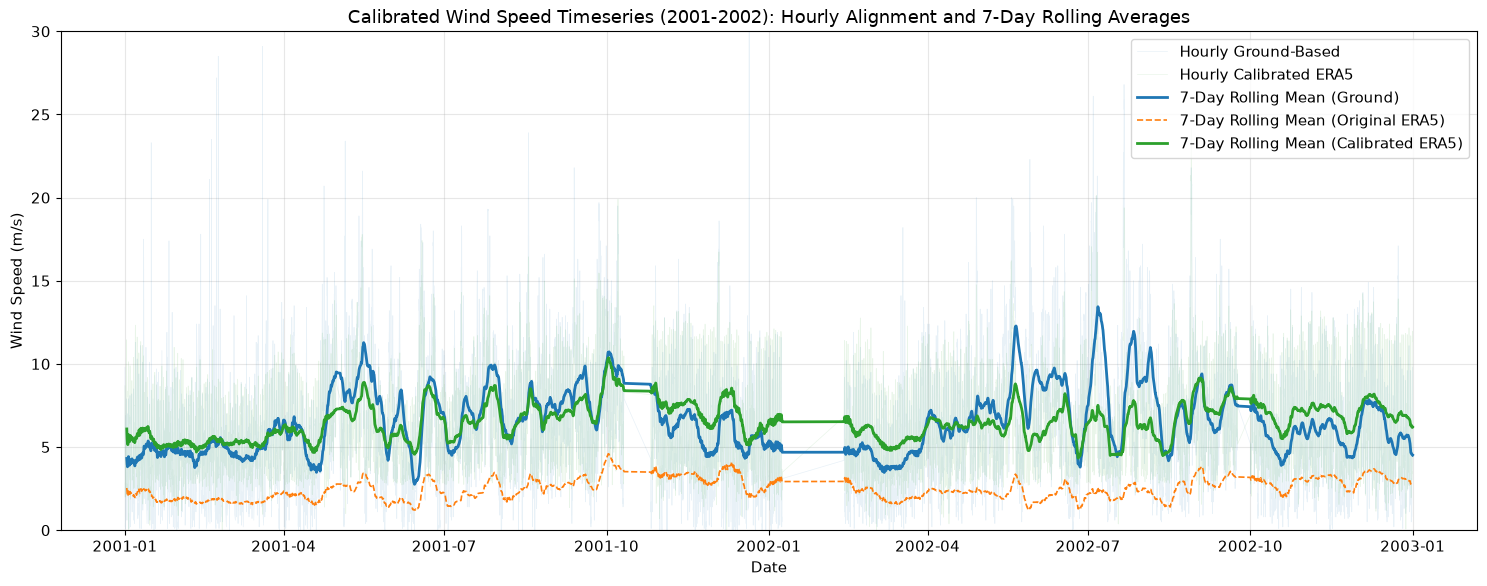

In [8]:
# ============================================================
# 8. TIMESERIES COMPARISON PLOT
# ============================================================
plt.figure(figsize=(15, 6))
plt.plot(merged_df['datetime'], merged_df['speed'], color='#1f77b4', alpha=0.1, label='Hourly Ground-Based', linewidth=0.5)
plt.plot(merged_df['datetime'], merged_df['era5_speed_calibrated'], color='#2ca02c', alpha=0.1, label='Hourly Calibrated ERA5', linewidth=0.5)

roll_window = 168
plt.plot(merged_df['datetime'], merged_df['speed'].rolling(roll_window, min_periods=24).mean(), 
         color='#1f77b4', label='7-Day Rolling Mean (Ground)', linewidth=2.0)
plt.plot(merged_df['datetime'], merged_df['era5_speed'].rolling(roll_window, min_periods=24).mean(), 
         color='#ff7f0e', label='7-Day Rolling Mean (Original ERA5)', linewidth=1.2, linestyle='--')
plt.plot(merged_df['datetime'], merged_df['era5_speed_calibrated'].rolling(roll_window, min_periods=24).mean(), 
         color='#2ca02c', label='7-Day Rolling Mean (Calibrated ERA5)', linewidth=2.0)

plt.title('Calibrated Wind Speed Timeseries (2001-2002): Hourly Alignment and 7-Day Rolling Averages')
plt.xlabel('Date')
plt.ylabel('Wind Speed (m/s)')
plt.legend(loc='upper right')
plt.ylim(0, 30)
plt.tight_layout()
plt.savefig('../data/exports/calibrated_timeseries_comparison.png', dpi=150)
plt.show()

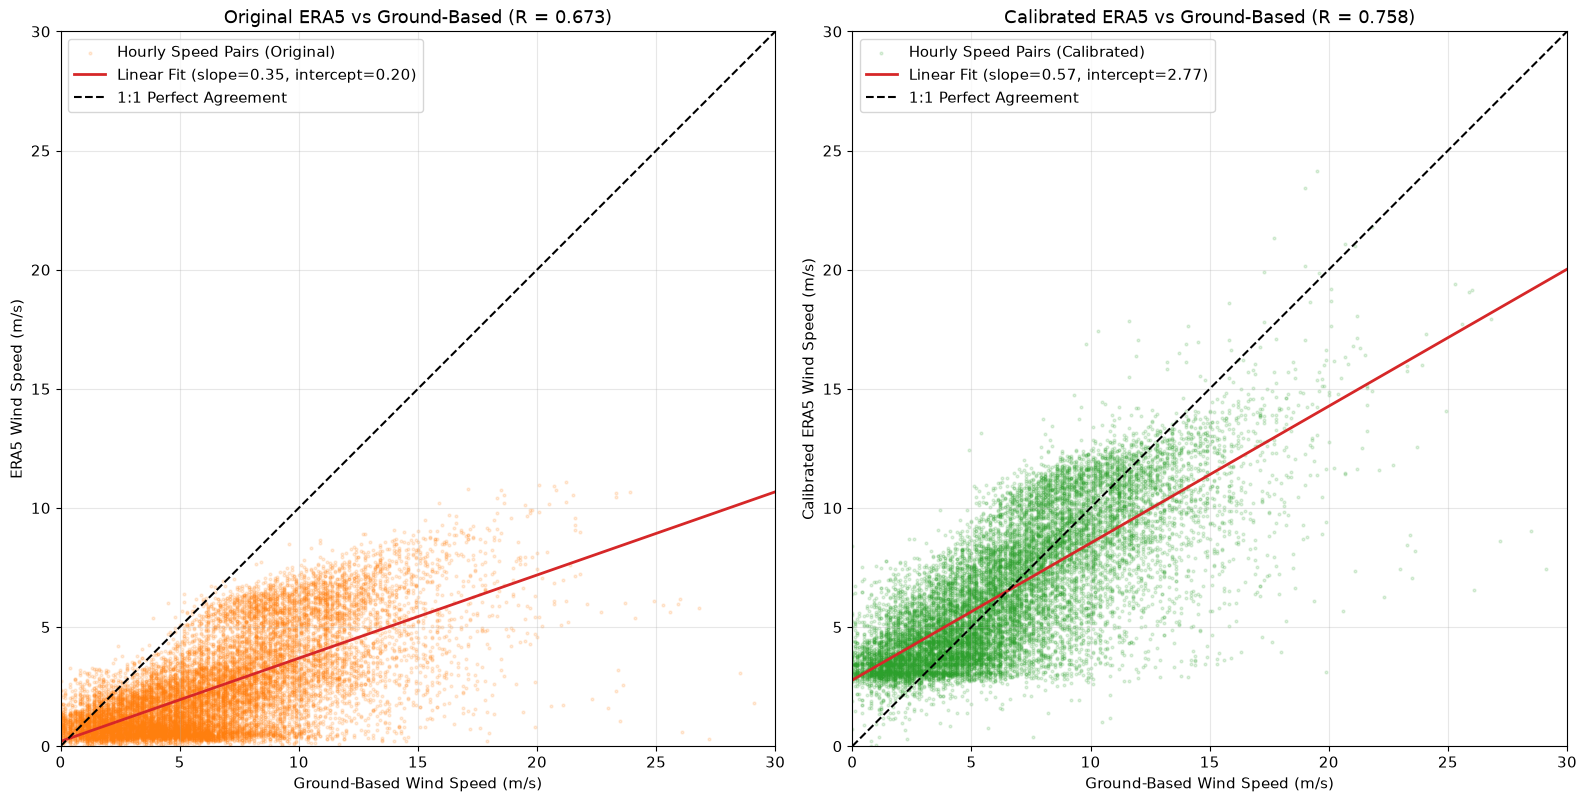

In [9]:
# ============================================================
# 9. SCATTER COMPARISON (ORIGINAL VS CALIBRATED)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
x_vals = np.linspace(0, 30, 100)

# Original Scatter
axes[0].scatter(merged_df['speed'], merged_df['era5_speed'], alpha=0.15, s=4, color='#ff7f0e', label='Hourly Speed Pairs (Original)')
slope_orig, intercept_orig = np.polyfit(merged_df['speed'], merged_df['era5_speed'], 1)
axes[0].plot(x_vals, slope_orig * x_vals + intercept_orig, color='#d62728', linewidth=2.0, 
         label=f'Linear Fit (slope={slope_orig:.2f}, intercept={intercept_orig:.2f})')
axes[0].plot([0, 30], [0, 30], 'k--', label='1:1 Perfect Agreement', linewidth=1.5)
axes[0].set_title(f'Original ERA5 vs Ground-Based (R = {metrics_orig[3]:.3f})')
axes[0].set_xlabel('Ground-Based Wind Speed (m/s)')
axes[0].set_ylabel('ERA5 Wind Speed (m/s)')
axes[0].set_xlim(0, 30)
axes[0].set_ylim(0, 30)
axes[0].set_aspect('equal', adjustable='box')
axes[0].legend(loc='upper left')

# Calibrated Scatter
axes[1].scatter(merged_df['speed'], merged_df['era5_speed_calibrated'], alpha=0.15, s=4, color='#2ca02c', label='Hourly Speed Pairs (Calibrated)')
slope_cal, intercept_cal = np.polyfit(merged_df['speed'], merged_df['era5_speed_calibrated'], 1)
axes[1].plot(x_vals, slope_cal * x_vals + intercept_cal, color='#d62728', linewidth=2.0, 
         label=f'Linear Fit (slope={slope_cal:.2f}, intercept={intercept_cal:.2f})')
axes[1].plot([0, 30], [0, 30], 'k--', label='1:1 Perfect Agreement', linewidth=1.5)
axes[1].set_title(f'Calibrated ERA5 vs Ground-Based (R = {metrics_cal[3]:.3f})')
axes[1].set_xlabel('Ground-Based Wind Speed (m/s)')
axes[1].set_ylabel('Calibrated ERA5 Wind Speed (m/s)')
axes[1].set_xlim(0, 30)
axes[1].set_ylim(0, 30)
axes[1].set_aspect('equal', adjustable='box')
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.savefig('../data/exports/calibrated_scatter_comparison.png', dpi=150)
plt.show()

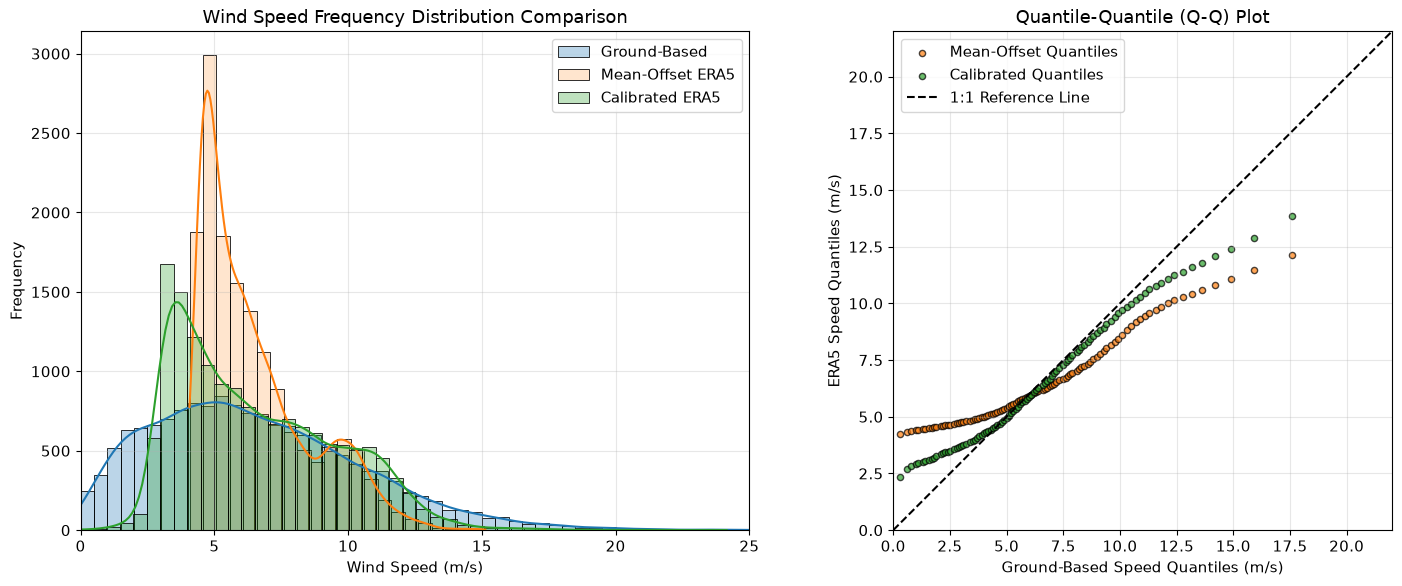

In [10]:
# ============================================================
# 10. DISTRIBUTION & QUANTILE COMPARISON
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Histograms / KDEs
sns.histplot(merged_df['speed'], color='#1f77b4', alpha=0.3, label='Ground-Based', kde=True, binwidth=0.5, ax=axes[0])
sns.histplot(merged_df['era5_speed_offset'], color='#ff7f0e', alpha=0.2, label='Mean-Offset ERA5', kde=True, binwidth=0.5, ax=axes[0])
sns.histplot(merged_df['era5_speed_calibrated'], color='#2ca02c', alpha=0.3, label='Calibrated ERA5', kde=True, binwidth=0.5, ax=axes[0])
axes[0].set_title('Wind Speed Frequency Distribution Comparison')
axes[0].set_xlabel('Wind Speed (m/s)')
axes[0].set_ylabel('Frequency')
axes[0].set_xlim(0, 25)
axes[0].legend()

# Quantile-Quantile (Q-Q) Plot
q_values = np.linspace(0.01, 0.99, 99)
q_pub = merged_df['speed'].quantile(q_values)
q_era5_offset = merged_df['era5_speed_offset'].quantile(q_values)
q_era5_cal = merged_df['era5_speed_calibrated'].quantile(q_values)

axes[1].scatter(q_pub, q_era5_offset, color='#ff7f0e', edgecolor='k', s=20, alpha=0.7, label='Mean-Offset Quantiles')
axes[1].scatter(q_pub, q_era5_cal, color='#2ca02c', edgecolor='k', s=20, alpha=0.7, label='Calibrated Quantiles')
axes[1].plot([0, 25], [0, 25], 'k--', label='1:1 Reference Line')
axes[1].set_title('Quantile-Quantile (Q-Q) Plot')
axes[1].set_xlabel('Ground-Based Speed Quantiles (m/s)')
axes[1].set_ylabel('ERA5 Speed Quantiles (m/s)')
axes[1].set_xlim(0, 22)
axes[1].set_ylim(0, 22)
axes[1].set_aspect('equal', adjustable='box')
axes[1].legend()

plt.tight_layout()
plt.savefig('../data/exports/calibrated_distribution_comparison.png', dpi=150)
plt.show()